# Утилизация автопарка и баланс спроса

**Данные синтетические и воспроизводимые.** Это портфельный кейс; он не использует и не описывает данные реального каршеринга.

## tl;dr

- В моделируемом периоде: **198,990 поездок**, утилизация **26.4%** и конверсия поиска в бронирование **63.9%**.
- Lost demand proxy — **4.4%** поисков без доступного автомобиля в зоне; это нижняя граница, а не полная оценка спроса.
- Первая гипотеза релокации: **Набережная → Деловой квартал**, вечер (17–21). Это кандидат для рандомизированного теста, а не доказанный эффект.

## Context & Methods

### Key Assumptions

- Период: 2025 год, локальные часы Europe/Moscow; генератор фиксирован seed.
- Доступность и занятость агрегированы до почасового статуса: поездка, начатая в час, занимает статусный час.
- `lost_demand_proxy` = поиски в зоне без доступного автомобиля / все поиски. Он не включает пользователей, которые не открыли приложение.
- Наблюдаемая связь доступности и конверсии не интерпретируется как причинная.

## Data

### 1. Load marts and join zone metadata

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
processed = ROOT / 'data' / 'processed'
raw = ROOT / 'data' / 'raw'
hour = pd.read_csv(processed / 'mart_zone_hour.csv', parse_dates=['hour_ts'])
zones = pd.read_csv(raw / 'zones.csv')
zone_hour = hour.merge(zones[['zone_id', 'zone_name', 'zone_type']], on='zone_id', how='left', validate='many_to_one')
assert zone_hour['zone_name'].notna().all()
zone_hour[['hour_ts', 'zone_name', 'available_car_minutes', 'rides_started', 'searches']].head()

,hour_ts,zone_name,available_car_minutes,rides_started,searches
0,2025-12-18 08:00:00,Деловой квартал,300.0,8,10.0
1,2025-12-18 09:00:00,Деловой квартал,120.0,5,9.0
2,2025-12-18 10:00:00,Деловой квартал,60.0,6,10.0
3,2025-12-18 11:00:00,Деловой квартал,0.0,2,7.0
4,2025-12-18 12:00:00,Деловой квартал,120.0,3,11.0


### 2. Validate grain and metric components

In [2]:
assert len(zone_hour) == zone_hour['hour_ts'].nunique() * zone_hour['zone_id'].nunique()
assert (zone_hour[['available_car_minutes', 'in_ride_minutes', 'searches']] >= 0).all().all()
zone_hour.groupby('status' if 'status' in zone_hour else 'day_type').size().head()

day_type
weekday    75168
weekend    29952
dtype: int64

## Results

### 3. Recalculate weekday/weekend metrics from numerators and denominators

In [3]:
components = ['available_car_minutes', 'in_ride_minutes', 'rides_started', 'searches', 'bookings', 'unserved_searches']
day_type = zone_hour.groupby('day_type', as_index=False)[components].sum()
day_type['utilization_rate'] = day_type['in_ride_minutes'] / (day_type['in_ride_minutes'] + day_type['available_car_minutes'])
day_type['conversion'] = day_type['bookings'] / day_type['searches']
day_type['lost_demand_proxy'] = day_type['unserved_searches'] / day_type['searches']
day_type[['day_type', 'utilization_rate', 'conversion', 'lost_demand_proxy']]

,day_type,utilization_rate,conversion,lost_demand_proxy
0,weekday,0.262944,0.625592,0.055525
1,weekend,0.268157,0.675716,0.014801


### 4. Availability and conversion (descriptive, not causal)

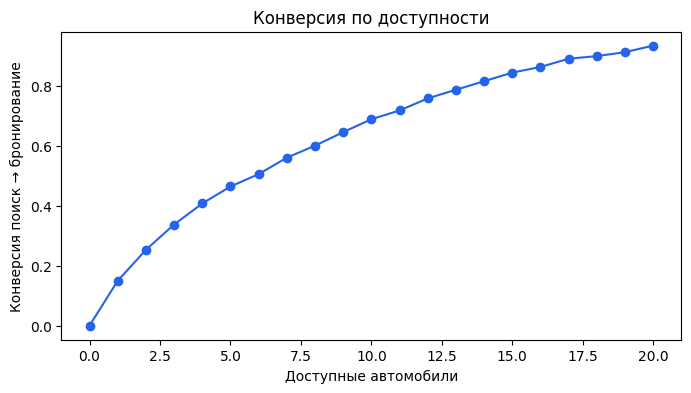

In [4]:
curve = (zone_hour.query('searches > 0')
    .assign(available_cars=lambda x: x['starting_available_cars'])
    .groupby('available_cars', as_index=False)[['bookings', 'searches']].sum())
curve['conversion'] = curve['bookings'] / curve['searches']
curve = curve.query('available_cars <= 20')
ax = curve.plot(x='available_cars', y='conversion', marker='o', color='#2563EB', legend=False, figsize=(8, 4))
ax.set(title='Конверсия по доступности', xlabel='Доступные автомобили', ylabel='Конверсия поиск → бронирование')
plt.show()

### 5. Inspect relocation hypotheses

In [5]:
priorities = pd.read_csv(ROOT / 'outputs' / 'priority_relocations.csv')
priorities[['day_type', 'hour_block', 'recipient_zone', 'donor_zone', 'lost_demand_proxy', 'recommended_cars', 'priority_score']].head(10)

,day_type,hour_block,recipient_zone,donor_zone,lost_demand_proxy,recommended_cars,priority_score
0,weekday,вечер (17–21),Деловой квартал,Набережная,0.275040,3,6049.20
1,weekday,вечер (17–21),Технопарк,Набережная,0.296232,3,4960.30
2,weekday,день (11–16),Деловой квартал,Набережная,0.131690,3,3475.10
3,weekday,день (11–16),Технопарк,Набережная,0.188748,3,3208.75
4,weekday,утро (07–10),Деловой квартал,Набережная,0.084362,2,2263.35
5,weekday,утро (07–10),Технопарк,Набережная,0.096834,2,1916.25
6,weekday,вечер (17–21),Центр,Набережная,0.022908,1,1287.10
7,weekday,утро (07–10),Южный жилой,Набережная,0.042704,1,915.45
8,weekend,вечер (17–21),Набережная,Деловой квартал,0.034144,1,662.95
9,weekday,день (11–16),Университетский,Набережная,0.012736,1,657.30


## Takeaways

- Использовать релокацию как экспериментальную гипотезу в самых напряжённых `зона × окно` и измерять её против стратифицированного контроля.
- Не переносить автомобили из зоны-донора, если в ней растёт lost demand proxy: это guardrail, а не побочный показатель.
- Для боевого решения нужны фактическая география, отмены, ETA, цена, свободные автомобили в радиусе и причина неуспешного бронирования.